# **TP1 - Variable Types & Descriptive Statistics**

<b>Exploratory Data Analysis & Unsuperivsed Learning </b><br>
**Course: Dr. HAS Sothea** <br> 
**TP: Ms. UANN Sreyvi** <br>

-------

**Objective**: This initial practical session is designed to enhance your understanding of various data variable types and the corresponding statistical and graphical tools suitable for each type.

---------

> **The `Jupyter Notebook` for this TP can be downloaded here: [TP1-Gapminder](https://hassothea.github.io/I5_EDA_ITC/TPs/TP1_Variable_Types_Descriptive_Statistics.ipynb)**.

-------

# 1. `Gapminder` dataset

[`Gapminder`](https://pypi.org/project/gapminder/) is an excerpt of data available at [https://gapminder.org](https://www.gapminder.org/). For each of $142$ countries (`country`), the package provides values for life expectancy (`lifeExp`), GDP per capita (`gdpPercap`), and population (`pop`), every five years, from $1952$ to $2007$ (`year`). It is initially used in [Jennifer Bryan's excellent `gapminder` teaching package for R](https://github.com/jennybc/gapminder/) ([`ggplot`](https://ggplot2.tidyverse.org/), [`tidyverse`](https://www.tidyverse.org/), and more). For more information about `gapminder`: 
- Documentation: [https://www.gapminder.org/data/documentation/](https://www.gapminder.org/data/documentation/)
- A short demonstration video is available here: [Hans Rosling's 200 Countries, 200 Years, 4 Minutes - The Joy of Stats - BBC Four](https://youtu.be/jbkSRLYSojo?si=qipg08VIi999hEgo).

In [3]:
# useful packages
import numpy as np
import pandas as pd

# %pip install gapminder  (for installing gapminder if you haven't had one)
from gapminder import gapminder
print(f"* Number of observations: {gapminder.shape[0]}")
gapminder.sample(3)

* Number of observations: 1704


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/gapminder/data.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


,country,continent,year,lifeExp,pop,gdpPercap
296,China,Asia,1992,68.690,1164970000,1655.784158
1157,Oman,Asia,1977,57.367,1004533,11848.343920
1647,Vietnam,Asia,1967,47.838,39463910,637.123289


----------

# 2. Variable types

`EDA` involves summarizing and visualizing data to uncover patterns, detect anomalies, and understand relationships between variables. Statistical summaries, such as mean, median, and standard deviation, are essential tools in this process.

- Which variables are considered quantitative and which are qualitative? 

> Hint: You can check the default column types by using `gapminder.dtypes`. But this may not be accurate because some categorical data may be encoded using numerical values.

In [4]:
gapminder.dtypes

country       object
continent     object
year           int64
lifeExp      float64
pop            int64
gdpPercap    float64
dtype: object

In [5]:
print(f"Quantitative columns: {gapminder.select_dtypes(include='number').columns.to_list()}")
print(f"Qualitative columns: {gapminder.select_dtypes(exclude='number').columns.to_list()}")

Quantitative columns: ['year', 'lifeExp', 'pop', 'gdpPercap']
Qualitative columns: ['country', 'continent']


> **Your response**: 
- **Quantitative**: `lifeExp` (continuous), `gdpPercap` (continuous), `pop` (discrete count, treated as continuous because of its huge range). 
- **Qualitative**: `country` (nominal, 142 levels) and `continent` (nominal, 5 levels).
- **`year`** is stored as an integer, but it is really an *ordered time index* (1952, 1957, … 2007, every 5 years). Its arithmetic (mean, std) has no real meaning, so we treat it as an ordinal/time variable and exclude it from the summaries. This is exactly the trap mentioned in the hint: `dtypes` says "number" but the semantics say "time label".

## 2.1 Quantitative variables

1. In year 2002, 
- Compute suitable statistics for each quantitative variable (excluding `year`) to obtain an overall summary.
- Recall the definitions of **skewness** and **kurtosis** introduced in the course. 
- Compute these metrics for each quantitative variable and explain the distribution of each variable based on these values.

In [6]:
data2002 = gapminder.query("year == 2002").copy()
data2002.head()

,country,continent,year,lifeExp,pop,gdpPercap
10,Afghanistan,Asia,2002,42.129,25268405,726.734055
22,Albania,Europe,2002,75.651,3508512,4604.211737
34,Algeria,Africa,2002,70.994,31287142,5288.040382
46,Angola,Africa,2002,41.003,10866106,2773.287312
58,Argentina,Americas,2002,74.340,38331121,8797.640716


In [7]:
data2002[['lifeExp', 'pop', 'gdpPercap']].describe()

,lifeExp,pop,gdpPercap
count,142.000000,1.420000e+02,142.000000
mean,65.694923,4.145759e+07,9917.848365
std,12.279823,1.408483e+08,11154.114865
min,39.193000,1.703720e+05,241.165876
25%,55.522250,4.173506e+06,1409.567264
50%,70.825500,1.037292e+07,5319.804524
75%,75.459250,2.654556e+07,13359.512258
max,82.000000,1.280400e+09,44683.975250


**Definitions.** With mean $\mu$ and standard deviation $\sigma$:

$$\text{Skew}(X)=\mathbb{E}\!\left[\left(\tfrac{X-\mu}{\sigma}\right)^{3}\right],\qquad \text{Kurt}(X)=\mathbb{E}\!\left[\left(\tfrac{X-\mu}{\sigma}\right)^{4}\right]$$

- **Skewness** measures asymmetry: $0$ = symmetric, $>0$ = long right tail (a few very large values), $<0$ = long left tail.
- **Kurtosis** measures tail heaviness. The normal law has $\text{Kurt}=3$, so `pandas` reports the **excess kurtosis** $\text{Kurt}-3$: $0$ = normal-like tails, $>0$ = heavy tails/outliers (leptokurtic), $<0$ = light tails (platykurtic).

In [8]:
num = ['lifeExp', 'pop', 'gdpPercap']
shape = pd.DataFrame({
    'skewness': data2002[num].skew(),
    'excess kurtosis': data2002[num].kurt(),
    'mean': data2002[num].mean(),
    'median': data2002[num].median(),
})
shape

,skewness,excess kurtosis,mean,median
lifeExp,-0.632298,-0.954877,6.569492e+01,7.082550e+01
pop,7.471563,59.604234,4.145759e+07,1.037292e+07
gdpPercap,1.258700,0.342356,9.917848e+03,5.319805e+03


> **Interpretation (2002)**
- **`lifeExp`**: skewness $\approx -0.63$ (moderate **left** skew) and excess kurtosis $\approx -0.95$ (light tails, flatter than normal). The mean (65.7) is below the median (70.8): most countries have a high life expectancy (70+), while a minority of (mostly African) countries drag the mean down. The distribution is flat and possibly **bimodal** (two groups: developing vs developed).
- **`pop`**: skewness $\approx 7.5$ and excess kurtosis $\approx 59.6$: extremely **right-skewed** with very heavy tails. The mean (41.5M) is 4× the median (10.4M) because of giants like China (1.28 billion) and India. The mean is not representative here; use the median/IQR or a log scale.
- **`gdpPercap`**: skewness $\approx 1.26$ (clear **right** skew), excess kurtosis $\approx 0.34$ (close to normal tails). The mean (≈ \$9,918) is almost twice the median (≈ \$5,320): many poor countries and a few rich ones (up to ≈ \$44,700). Std $>$ mean/2 shows strong inequality.

2. Graphically represent the distribution of each variable for the year $2002$. After plotting the distributions, provide a brief explanation for each variable.

In [9]:
import plotly.express as px
from plotly.subplots import make_subplots
import plotly.graph_objects as go

fig = make_subplots(rows=1, cols=4, subplot_titles=['lifeExp', 'gdpPercap', 'pop', 'log10(pop)'])
fig.add_trace(go.Histogram(x=data2002['lifeExp'], nbinsx=20, name='lifeExp'), row=1, col=1)
fig.add_trace(go.Histogram(x=data2002['gdpPercap'], nbinsx=30, name='gdpPercap'), row=1, col=2)
fig.add_trace(go.Histogram(x=data2002['pop'], nbinsx=30, name='pop'), row=1, col=3)
fig.add_trace(go.Histogram(x=np.log10(data2002['pop']), nbinsx=20, name='log10(pop)'), row=1, col=4)
fig.update_layout(width=1100, height=320, title='Distributions of the quantitative variables in 2002', showlegend=False)
fig.show()

px.box(data2002.melt(value_vars=['lifeExp']), y='value', x='variable', points='all').update_layout(width=300, height=300, title='lifeExp boxplot').show()

> **Explanation**
- **`lifeExp`**: the histogram piles up on the right (70–80 years) with a long tail to the left (40–55 years) and a flat shape, consistent with negative skewness and negative kurtosis. Two groups of countries coexist.
- **`gdpPercap`**: a big spike at low values (< \$5,000) and a long right tail: typical right-skewed income distribution, a few rich countries.
- **`pop`**: almost all countries are squeezed in the first bin and two points (China, India) are far away. The histogram on the raw scale is unreadable, so the **log scale** is shown: it is then roughly bell-shaped, showing that population is approximately *log-normal*.

3. According to the data, in 2002:
- Which country is the richest? 
- Which country is the poorest?
- Which country is the healthiest?
- Which country is the unhealthiest?

In [10]:
def extremes(d):
    out = []
    for col, hi, lo in [('gdpPercap', 'Richest', 'Poorest'), ('lifeExp', 'Healthiest', 'Unhealthiest')]:
        out.append((hi, d.loc[d[col].idxmax(), 'country'], d[col].max()))
        out.append((lo, d.loc[d[col].idxmin(), 'country'], d[col].min()))
    return pd.DataFrame(out, columns=['question', 'country', 'value']).set_index('question')
extremes(data2002)

,country,value
question,,
Richest,Norway,44683.975250
Poorest,"Congo, Dem. Rep.",241.165876
Healthiest,Japan,82.000000
Unhealthiest,Zambia,39.193000


> **Answer (2002)**: richest = **Norway** (≈ \$44,684 per capita); poorest = **Congo, Dem. Rep.** (≈ \$241); healthiest = **Japan** (82.0 years); unhealthiest = **Zambia** (39.2 years). The gap is huge: Norway is ~185× richer than DR Congo and Japan lives twice as long as Zambia.

4. Repeat the previous question for the year 1977. Before computing, can you guess which country had the lowest life expectancy around that year?

In [11]:
extremes(gapminder.query("year == 1977"))

,country,value
question,,
Richest,Kuwait,59265.47714
Poorest,Myanmar,371.00000
Healthiest,Iceland,76.11000
Unhealthiest,Cambodia,31.22000


> **Answer (1977)**: the lowest life expectancy is **Cambodia** (31.2 years): this is the period of the Khmer Rouge regime (1975–1979), when roughly a quarter of the population died from executions, famine and forced labour. (A natural guess would be a poor African country, but the genocide makes Cambodia the outlier.) In 1977 the richest is **Kuwait** (≈ \\$59,265), the poorest **Myanmar** (≈ \\$371) and the healthiest **Iceland** (76.1 years).

## 2.2. Qualitative variables

Qualitative variables are simpler than the quantitative ones, as we primarily focus on the proportion or frequency of each category. In our dataset, the existing qualitative variables are not suitable for analysis because they are repeated each year. Therefore, we will create three new qualitative variables associated with the three quantitative columns by copping them into three categories each.

In year 2002,

1. Add the following three variables to the `gapminder` dataset by grouping each quantitative variable into $3$ groups.
- Create variable `gdpQual` with three categories: [**"developing"**, **"moderate"**, **"developed"**] using variable `gdpPercap`.
- Create variable `popQual` with three categories: [**"small"**, **"medium"**, **"large"**] using variable `pop`.
- Create variable `lifeExpQual` with three categories: [**"unhealthy"**, **"moderate"**, **"healthy"**] using variable `lifeExp`.

> Hint: you may find `pd.cut` function helpful.

In [12]:
data2002['gdpQual'] = pd.cut(data2002['gdpPercap'], bins=3, labels=["developing", "moderate", "developed"])
data2002['popQual'] = pd.cut(data2002['pop'], bins=3, labels=["small", "medium", "large"])
data2002['lifeExpQual'] = pd.cut(data2002['lifeExp'], bins=3, labels=["unhealthy", "moderate", "healthy"])

In [13]:
data2002.head()

,country,continent,year,lifeExp,pop,gdpPercap,gdpQual,popQual,lifeExpQual
10,Afghanistan,Asia,2002,42.129,25268405,726.734055,developing,small,unhealthy
22,Albania,Europe,2002,75.651,3508512,4604.211737,developing,small,healthy
34,Algeria,Africa,2002,70.994,31287142,5288.040382,developing,small,healthy
46,Angola,Africa,2002,41.003,10866106,2773.287312,developing,small,unhealthy
58,Argentina,Americas,2002,74.340,38331121,8797.640716,developing,small,healthy


2. Compute the appropriate statistical values and graphically represent the distribution of each newly created qualitative variable.

In [14]:
qual = ['gdpQual', 'popQual', 'lifeExpQual']
for c in qual:
    print(pd.DataFrame({'count': data2002[c].value_counts(), 'proportion': data2002[c].value_counts(normalize=True).round(3)}), '\n')

            count  proportion
gdpQual                      
developing    108       0.761
moderate       19       0.134
developed      15       0.106 

         count  proportion
popQual                   
small      140       0.986
large        2       0.014
medium       0       0.000 

             count  proportion
lifeExpQual                   
healthy         84       0.592
unhealthy       32       0.225
moderate        26       0.183 



In [15]:
data2002['continent'].value_counts()

continent
Africa      52
Asia        33
Europe      30
Americas    25
Oceania      2
Name: count, dtype: int64

- Graphically represent them and describe the graph.

In [16]:
fig = make_subplots(rows=1, cols=3, subplot_titles=['gdpQual', 'lifeExpQual', 'popQual'])
for j, (c, order) in enumerate([('gdpQual', ["developing", "moderate", "developed"]),
                                ('lifeExpQual', ["unhealthy", "moderate", "healthy"]),
                                ('popQual', ["small", "medium", "large"])], start=1):
    p = data2002[c].value_counts(normalize=True).reindex(order)
    fig.add_trace(go.Bar(x=p.index.astype(str), y=p.values), row=1, col=j)
fig.update_layout(width=1000, height=350, showlegend=False, title='Bar charts of the qualitative variables in 2002')
fig.update_yaxes(title_text='proportion', col=1)
fig.show()

> **Description**
`pd.cut(bins=3)` cuts the *range* into 3 **equal-width** intervals (not equal-size groups), so the categories reflect how spread out the data is.
- **`gdpQual`**: 108 countries (76%) are "developing", 19 (13%) "moderate", 15 (11%): the bar chart is strongly decreasing, which mirrors the right-skewed GDP.
- **`lifeExpQual`**: 84 countries (59%) "healthy", 26 "moderate", 32 "unhealthy": the bars are increasing, mirroring the left-skewed life expectancy.
- **`popQual`**: 140 countries are "small", 0 "medium" and only 2 "large" (China, India). Because of the outliers, equal-width bins are useless here. `pd.qcut` (quantile-based, equal-size groups) would be a better choice for such a variable.

*Note*: for a qualitative variable we use **frequencies/proportions and bar charts** (not mean/histogram).

---------

# 3. Time evolution

`Gapminder` captures global changes from $1952$ to $2007$. It is more insightful to examine how these variables evolve over time.

## 3.1. Evolution of quantitative columns

1. Create a line plot of `lifeExp` for the five continents from $1952$ to $2007$ using `sns.lineplot`. What observations can you make from the plot?

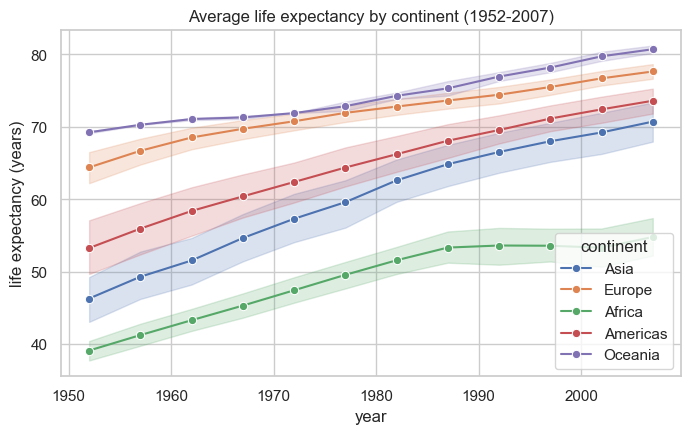

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_theme(style='whitegrid')

# Qualitative versions on the WHOLE dataset (same fixed thresholds for every year => comparable over time)
gapminder = gapminder.copy()
gapminder['gdpQual'] = pd.cut(gapminder['gdpPercap'], bins=3, labels=["developing", "moderate", "developed"])
gapminder['popQual'] = pd.cut(gapminder['pop'], bins=3, labels=["small", "medium", "large"])
gapminder['lifeExpQual'] = pd.cut(gapminder['lifeExp'], bins=3, labels=["unhealthy", "moderate", "healthy"])

plt.figure(figsize=(8, 4.5))
sns.lineplot(data=gapminder, x='year', y='lifeExp', hue='continent', marker='o')
plt.title('Average life expectancy by continent (1952-2007)')
plt.ylabel('life expectancy (years)')
plt.show()

> **Observations**
- Every continent gains life expectancy over 55 years: it is a **global** improvement (e.g. Asia 46 → 71, Americas 53 → 74).
- The ranking is stable: Oceania/Europe on top (≈ 78–81 years in 2007), then Americas, Asia, and Africa at the bottom (≈ 55).
- **Asia catches up fastest** (+24 years), reducing the gap with Europe. 
- **Africa nearly stagnates after 1992** (53.6 → 54.8) because of the HIV/AIDS epidemic and conflicts, so the gap with the other continents widens again.
- The shaded band is the 95% confidence interval across countries: it is widest for Africa and Asia, meaning large differences *within* these continents.

2. Repeat the same process with `pop`, and then with `gdpPercap`. Provide your comments for each case.

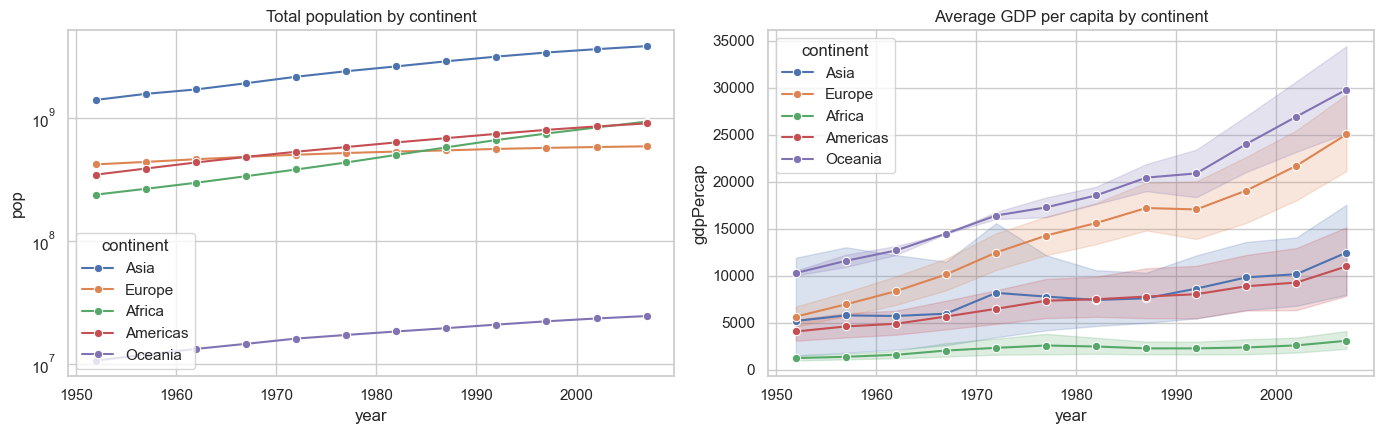

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

# population: total per continent (sum of countries)
sns.lineplot(data=gapminder, x='year', y='pop', hue='continent', estimator='sum', errorbar=None, marker='o', ax=ax[0])
ax[0].set_title('Total population by continent'); ax[0].set_yscale('log')

# GDP per capita: average per continent
sns.lineplot(data=gapminder, x='year', y='gdpPercap', hue='continent', marker='o', ax=ax[1])
ax[1].set_title('Average GDP per capita by continent')
plt.tight_layout(); plt.show()

> **Comments**
- **Population** (total per continent, log scale): all continents grow. **Asia dominates** (1.4 billion → 3.8 billion) and grows fastest in absolute terms; **Africa** more than quadruples (238M → 930M) and is the fastest in relative terms, so it overtakes Europe and the Americas. **Europe** is almost flat (418M → 586M) and **Oceania** is tiny (11M → 25M). (Note that the 142-country sample is not exhaustive.)
- **GDP per capita**: Europe and Oceania increase strongly (Europe ≈ \$5,700 → \$25,000), especially after 1960, and the gap with the rest widens: **divergence**. Asia and the Americas grow at a moderate pace, and **Africa stays nearly flat** (≈ \$1,250 → \$3,100). The confidence bands are very large for Asia (it contains both Kuwait/Japan and Myanmar/Afghanistan), showing strong within-continent inequality.

3. Plot the evolution of each of the three quantitative variables for **Cambodia** vs **Thailand**. Describe the graphs.

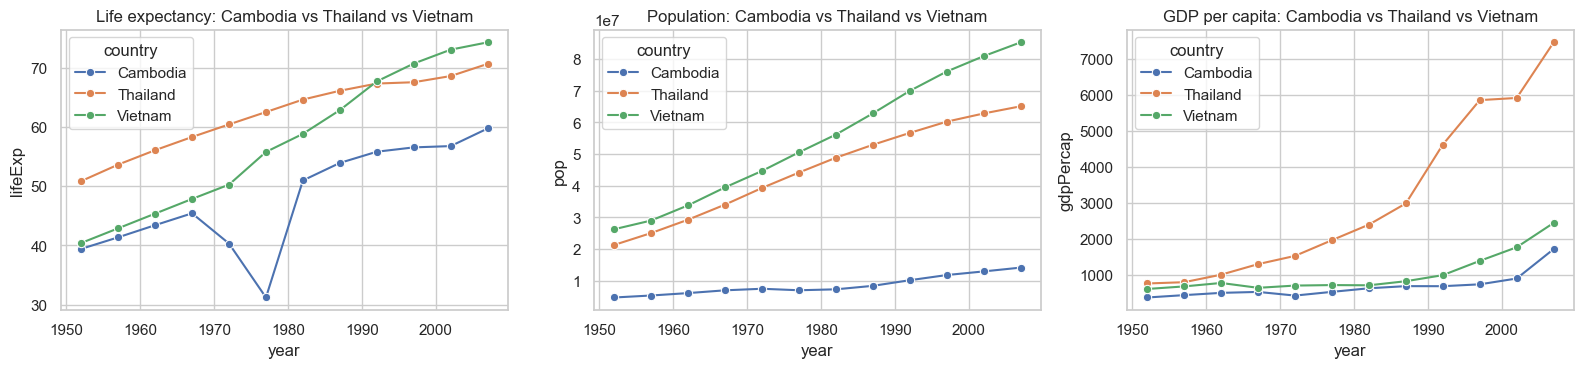

In [26]:
cmp = gapminder[gapminder.country.isin(['Cambodia', 'Thailand','Vietnam'])]
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, (v, t) in zip(ax, [('lifeExp', 'Life expectancy'), ('pop', 'Population'), ('gdpPercap', 'GDP per capita')]):
    sns.lineplot(data=cmp, x='year', y=v, hue='country', marker='o', ax=a)
    a.set_title(f'{t}: Cambodia vs Thailand vs Vietnam')
plt.tight_layout(); plt.show()

> **Description**
- **Life expectancy**: Thailand rises smoothly from 51 to 71 years. Cambodia starts lower (39), grows until 1967 and then **collapses to 31 in 1977** (Khmer Rouge genocide and civil war), before recovering quickly to 60 in 2007. A 11-year gap with Thailand remains.
- **Population**: Thailand grows steadily (21M → 65M). Cambodia grows more slowly (4.7M → 14M) and even **decreases around 1977**, the demographic trace of the genocide.
- **GDP per capita**: Thailand takes off from the 1960s (≈ \$760 → \$7,500, with a flat period 1997-2002 after the Asian financial crisis). Cambodia stays stagnant below \$900 for most of the period and only starts growing after 2002 (≈ \$1,700 in 2007). Thailand is ≈ 4× richer in 2007.

## 3.2. Evolution of qualitative columns

1. Visualize the evolution of `lifeExpQual` column in **Asia** from 1952 to 2007. What do you observe?

In [20]:
def plot_evolution(df, var, title, order):
    """Stacked bar chart of the yearly proportion of each category of `var`."""
    ct = pd.crosstab(df['year'], df[var], normalize='index').reindex(columns=order, fill_value=0) * 100
    fig = px.bar(ct, x=ct.index.astype(str), y=order, barmode='stack',
                 labels={'x': 'year', 'value': '% of countries', 'variable': var}, title=title)
    fig.update_layout(width=650, height=380)
    return fig

orders = {'lifeExpQual': ["unhealthy", "moderate", "healthy"],
          'popQual': ["small", "medium", "large"],
          'gdpQual': ["developing", "moderate", "developed"]}
asia = gapminder.query("continent == 'Asia'")
plot_evolution(asia, 'lifeExpQual', 'Evolution of lifeExpQual in Asia', orders['lifeExpQual']).show()

> **Observation (Asia)**: in 1952 about 42% of Asian countries are "unhealthy", 52% "moderate" and only 6% "healthy". The "unhealthy" group disappears very quickly (6% in 1977, 0% in 2007) and the "healthy" group takes over: 39% in 1977, 73% in 1997 and **85% in 2007**. This is the categorical view of the rise of life expectancy: the whole distribution shifts from the left to the right of the scale.

2. Do the same with `popQual` and `dgpQual` columns.

In [21]:
plot_evolution(asia, 'popQual', 'Evolution of popQual in Asia', orders['popQual']).show()

In [22]:
plot_evolution(asia, 'gdpQual', 'Evolution of gdpQual (typo "dgpQual" in the TP) in Asia', orders['gdpQual']).show()

> **Observation (Asia)**
- **`popQual`**: almost constant. About 94-97% of countries stay "small". China is already "medium" in 1952 and India joins from 1962; both become "large" later (6% of countries in 2007). The equal-width cut is dominated by these two giants, so the variable carries little information.
- **`gdpQual`**: the continent is **stuck in "developing"**: 97% in 1952 and still 91% in 2007. Only Kuwait is "developed" in 1952 (3%, thanks to oil), and in 2007 Hong Kong, Kuwait and Singapore are "moderate" (9%). Because Kuwait's very high GDP stretches the range of the bins, the thresholds are high and almost every country is "developing", which hides the real growth of Asian economies.

3. Visualize the evolution of the three qualitative columns above for African countries from 1952 to 2007.

In [23]:
africa = gapminder.query("continent == 'Africa'")
for v, t in [('lifeExpQual', 'lifeExpQual'), ('popQual', 'popQual'), ('gdpQual', 'gdpQual')]:
    plot_evolution(africa, v, f'Evolution of {t} in Africa', orders[v]).show()

> **Observation (Africa)**
- **`lifeExpQual`**: in 1952, 87% of African countries are "unhealthy". The big change happens by 1977 (only 19% unhealthy, 77% "moderate"). After that progress is **slow**: in 2007, 12% are "unhealthy", 67% "moderate" and only 21% "healthy". Compare with Asia, where 85% are "healthy": Africa has left the lowest category but has not reached the top one.
- **`popQual`**: 100% "small" in every year. Even Nigeria and Egypt are far below the equal-width threshold, so this variable gives no information for Africa.
- **`gdpQual`**: 100% "developing" in every year, 1952 to 2007. With these thresholds, no African country ever leaves the lowest income category, which is consistent with the nearly flat average GDP per capita seen in section 3.1.

# Further readings
- Gapminder documentation: [https://www.gapminder.org/data/documentation/](https://www.gapminder.org/data/documentation/)
- A short demonstration video is available here: [Hans Rosling's 200 Countries, 200 Years, 4 Minutes - The Joy of Stats - BBC Four](https://youtu.be/jbkSRLYSojo?si=qipg08VIi999hEgo).
- Graphical tools:
    - [`matplotlib`](https://matplotlib.org/stable/index.html)
    - [`seaborn`](https://seaborn.pydata.org/)
    - [`https://plotly.com/python/`](https://plotly.com/python/)